FOOD WASTE MODEL RESULTS
------------------------
Target: waste_units
Training rows: 1440
Testing rows: 360
MAE: 2.985
RMSE: 6.735
R2 Score: 0.025

Predictions saved to ml/outputs/food_waste_predictions.csv
Model saved to ml/models/food_waste_model.pkl


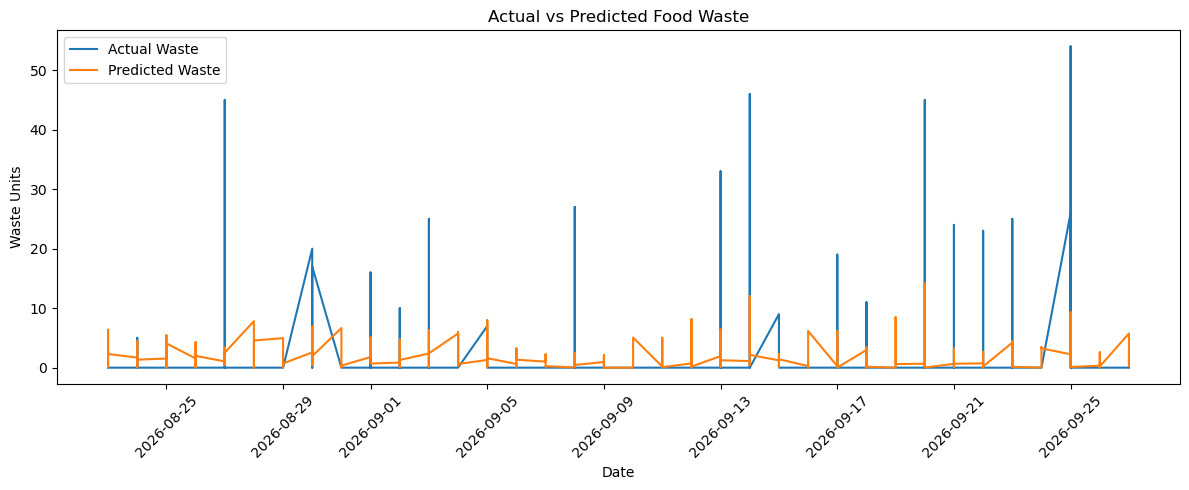


Top Important Features:
sales_rate         0.165790
temperature_c      0.161655
stock_available    0.107017
day                0.096417
opening_stock      0.095030
units_sold         0.072449
day_of_week        0.054849
units_received     0.045730
days_to_expiry     0.043359
expiry_urgency     0.040664
dtype: float64


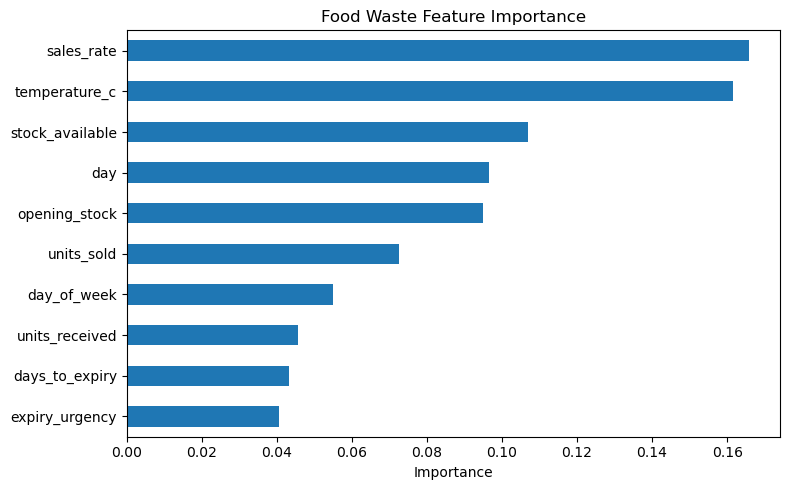


Sample predictions:
        date  actual_waste_units  predicted_waste_units
0 2026-08-23                   0               1.311690
1 2026-08-23                   0               0.491458
2 2026-08-23                   0               0.385000
3 2026-08-23                   0               2.268667
4 2026-08-23                   0               0.423542
5 2026-08-23                   0               0.138333
6 2026-08-23                   0               4.368750
7 2026-08-23                   0               0.971792
8 2026-08-23                   0               6.386476
9 2026-08-23                   0               2.292155


In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = r"ml\data\processed\perishable_features.csv"

if not os.path.exists(data_path):
    data_path = r"..\data\processed\perishable_features.csv"

df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()

target = "waste_units"

if target not in df.columns:
    raise ValueError("The dataset does not contain waste_units.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df[target] = pd.to_numeric(df[target], errors="coerce")

df = df.dropna(subset=["date", target]).copy()
df = df.sort_values("date").reset_index(drop=True)
df[target] = df[target].clip(lower=0)

df["day"] = df["date"].dt.day
df["year"] = df["date"].dt.year

features = [
    "product_id",
    "category",
    "opening_stock",
    "units_received",
    "units_sold",
    "unit_price",
    "discount_pct",
    "days_to_expiry",
    "temperature_c",
    "day_of_week",
    "month",
    "stock_available",
    "sales_rate",
    "expiry_urgency",
    "day",
    "year"
]

features = [col for col in features if col in df.columns]

X = df[features].copy()
y = df[target].copy()

X = pd.get_dummies(X, columns=[
    col for col in X.select_dtypes(include=["object"]).columns
], dtype=int)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X_train, y_train)

predictions = np.maximum(model.predict(X_test), 0)

print("FOOD WASTE MODEL RESULTS")
print("------------------------")
print("Target:", target)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))

if len(y_test) > 1:
    print("R2 Score:", round(r2_score(y_test, predictions), 3))

results = pd.DataFrame({
    "date": df["date"].iloc[split_index:].values,
    "actual_waste_units": y_test.values,
    "predicted_waste_units": predictions
})

os.makedirs("ml/outputs", exist_ok=True)
os.makedirs("ml/models", exist_ok=True)

results.to_csv("ml/outputs/food_waste_predictions.csv", index=False)

joblib.dump(model, "ml/models/food_waste_model.pkl")
joblib.dump(list(X.columns), "ml/models/food_waste_features.pkl")

print("\nPredictions saved to ml/outputs/food_waste_predictions.csv")
print("Model saved to ml/models/food_waste_model.pkl")

plt.figure(figsize=(12, 5))
plt.plot(results["date"], results["actual_waste_units"], label="Actual Waste")
plt.plot(results["date"], results["predicted_waste_units"], label="Predicted Waste")
plt.xlabel("Date")
plt.ylabel("Waste Units")
plt.title("Actual vs Predicted Food Waste")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop Important Features:")
print(importance.head(10))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Food Waste Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nSample predictions:")
print(results.head(10))
